# 03 线性回归

本篇对应原资料 `03_机器学习/03-线性回归`，依据 `01-讲义/线性回归.pptx` 和 `02-笔记/线性回归.md` 整理。学习顺序沿用课程：线性回归介绍 → 损失函数与数学复习 → 正规方程、梯度下降 → 回归评估 → 波士顿房价案例 → 欠拟合、过拟合与正则化。

资料：[机器学习课程](https://pan.baidu.com/s/1NmWli9KoAeYtlpXTzhw-Jg?pwd=1234)，提取码 `1234`。教学图直接嵌入本笔记；代码放在 Markdown 围栏中供阅读和复制。示例依赖 NumPy、pandas、Matplotlib、scikit-learn。

读完应能解释“模型、损失、优化、评估”的区别，推导一次梯度更新，独立完成“划分数据 → 预处理 → 训练 → 预测 → 评估”的回归流程，并通过验证数据选择多项式次数和正则化强度。原课中的旧 API 与计算笔误在对应位置注明。

## 1. 线性回归：从特征预测连续数值

**线性回归（Linear Regression）**用一个或多个特征的加权组合描述目标值，学习特征与目标之间的关系。例如，根据身高预测体重、根据房屋属性预测价格。

一元线性回归只有一个输入特征：

$$
\hat y=kx+b
$$

多元线性回归有多个输入特征：

$$
\hat y=w_1x_1+w_2x_2+\cdots+w_px_p+b=\boldsymbol w^\mathsf T\boldsymbol x+b
$$

| 符号 | 含义 | 在身高预测中的例子 |
|---|---|---|
| $x$ 或 $\boldsymbol x$ | 输入特征 | 身高 |
| $y$ | 真实目标 | 实测体重 |
| $\hat y$ | 模型预测 | 预测体重 |
| $w$、$k$ | 从训练数据中学习的权重 | 直线斜率 |
| $b$ | 截距，也称偏置 | 身高为 0 时模型的数学输出 |

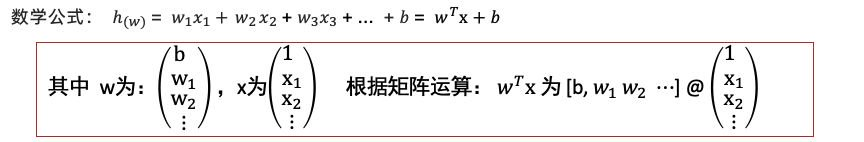

**线性指模型对待学习参数是线性的。** 原课“$w$ 的零次幂”表述不准确；模型中的权重以一次形式参与组合。即便把特征换成 $x,x^2$，$\hat y=w_1x+w_2x^2+b$ 仍然对参数线性，图像可以是曲线。

截距有数学意义，但不一定具有现实解释；不能把身高为 0 时的预测体重当作真实结论。

### 1.1 身高与体重：先找规律，再预测

原课给出以下五个已知样本，要求预测身高为 176 的新样本：

| 编号 | 身高 $x$（cm） | 体重 $y$（kg） |
|---|---:|---:|
| 1 | 160 | 56.3 |
| 2 | 166 | 60.6 |
| 3 | 172 | 65.1 |
| 4 | 174 | 68.5 |
| 5 | 180 | 75.0 |
| 待预测 | 176 | ? |

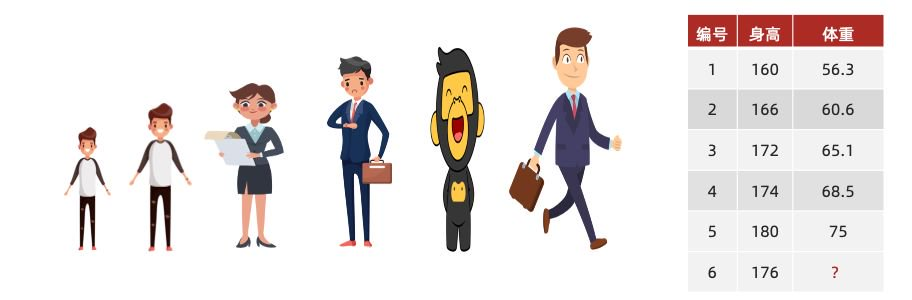

一条直线通常无法穿过所有观测点。我们希望找到一条整体误差较小的直线，再代入新样本的身高。

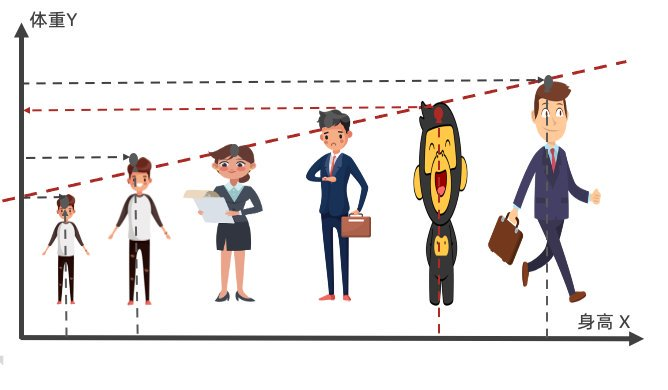

课程先假设 $\hat y=0.9x-93$，代入 176 得到 **65.4 kg**。这是讲解预测过程的假设直线；真正通过这五个样本最小二乘拟合的结果约为 **70.30 kg**，后文会推导。

### 1.2 用 LinearRegression 完成第一次预测

`fit(X, y)` 学习权重，`predict(X_new)` 使用已学到的参数预测。scikit-learn 中 `X` 通常是二维数组：形状为 `(样本数, 特征数)`；单目标 `y` 通常是一维数组。

```python
import numpy as np
from sklearn.linear_model import LinearRegression

X = np.array([[160], [166], [172], [174], [180]], dtype=float)
y = np.array([56.3, 60.6, 65.1, 68.5, 75.0])

model = LinearRegression(fit_intercept=True)
model.fit(X, y)

print("斜率:", model.coef_[0])
print("截距:", model.intercept_)
print("预测体重:", model.predict([[176]])[0])
```

按上述数据核算：

$$
k\approx0.92942177,\quad b\approx-93.27346939,\quad
\hat y(176)\approx70.30476190
$$

`coef_` 和 `intercept_` 是训练后属性，必须先 `fit`。`predict([[176]])` 中的双层方括号表示“1 个样本、1 个特征”。

这只有五个教学样本，适合观察拟合过程；不能据此证明模型对所有人群都有相同的预测效果。

## 2. 损失函数：怎样判断一条线是否拟合得好

第 $i$ 个样本的残差记作：

$$
e_i=\hat y_i-y_i
$$

残差可能为正，也可能为负。直接把残差相加会相互抵消，因此普通最小二乘使用**平方残差**：

$$
\mathrm{SSE}=\sum_{i=1}^{m}(\hat y_i-y_i)^2,\qquad
\mathrm{MSE}=\frac1m\sum_{i=1}^{m}(\hat y_i-y_i)^2
$$

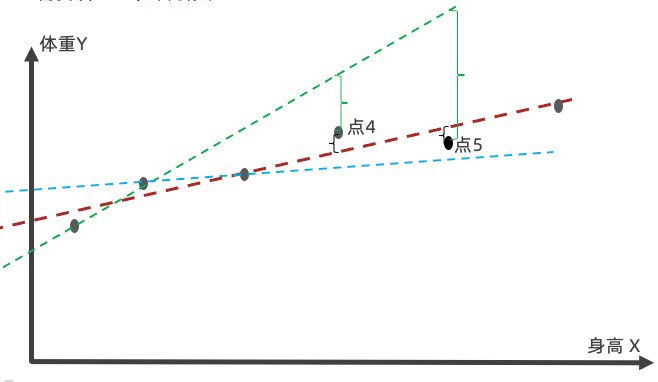

推导梯度时，常把目标写成：

$$
J(\boldsymbol w,b)=\frac1{2m}
\sum_{i=1}^{m}\left(\boldsymbol w^\mathsf T\boldsymbol x_i+b-y_i\right)^2
$$

前面的 $1/2$ 用来抵消求导产生的 2。在无正则项时，SSE、MSE 和这个 $J$ 的最优参数相同；它们的数值和梯度尺度不同，因此同一学习率对应的更新步长也不同。

学习过程可以分成三个问题：**模型**规定如何计算预测；**损失函数**衡量预测偏差；**优化算法**寻找使损失较小的参数。后文的 MAE、MSE、RMSE 也可作为训练完成后的评估指标。

## 3. 必要的数学复习

### 3.1 导数：函数在当前位置如何变化

导数表示瞬时变化率，也就是曲线在某一点的切线斜率：

$$
f'(x)=\lim_{\Delta x\to0}
\frac{f(x+\Delta x)-f(x)}{\Delta x}
$$

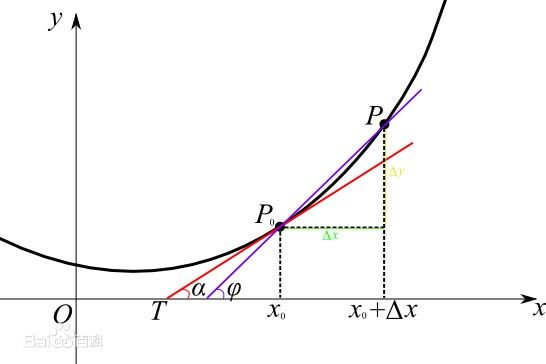

例如 $f(x)=x^2$，导数 $f'(x)=2x$。$x>0$ 时，减小 $x$ 能使函数下降；$x<0$ 时，增大 $x$ 能使函数下降。

常用求导规则：

| 函数/运算 | 导数 |
|---|---|
| 常数 $c$ | $0$ |
| $x^n$ | $nx^{n-1}$ |
| $af(x)+bg(x)$ | $af'(x)+bg'(x)$ |
| $f(x)g(x)$ | $f'(x)g(x)+f(x)g'(x)$ |
| $f(g(x))$ | $f'(g(x))g'(x)$ |

**导数为 0 只说明这里是一个驻点。** 例如 $x^3$ 在 0 处导数为 0，却没有极大值或极小值。对于无约束、可微、凸的平方损失，梯度为 0 才能进一步确定为全局最小点；是否唯一还取决于数据矩阵的秩。

### 3.2 偏导数、链式法则与梯度

当 $J$ 有多个参数时，对其中一个参数求导，并把其他参数暂时看成常数，得到偏导数。将所有偏导数排列起来，得到梯度。

对 $\hat y_i=kx_i+b$、$e_i=kx_i+b-y_i$：

$$
\frac{\partial J}{\partial k}
=\frac1m\sum_{i=1}^{m}e_ix_i,\qquad
\frac{\partial J}{\partial b}
=\frac1m\sum_{i=1}^{m}e_i
$$

第一条公式来自链式法则：

$$
\frac{\partial e_i^2}{\partial k}
=2e_i\frac{\partial e_i}{\partial k}
=2e_ix_i
$$

**梯度的方向是函数在当前位置增长最快的方向；负梯度是局部下降最快的方向。** 这里的方向位于参数空间，表示应该怎样调整 $k,b$，并不是让原始样本在身高坐标轴上移动。

### 3.3 标量、向量、矩阵、张量与范数

| 表示 | 含义 | 常见 NumPy 形状 |
|---|---|---|
| 标量 | 一个数 | `()` |
| 向量 | 一组有序数 | `(p,)`，也可显式表示为 `(p,1)` |
| 矩阵 | 行列排列的数 | `(m,p)` |
| 张量 | 多维数组的推广 | 例如 `(批次, 高, 宽, 通道)` |

数学推导里，单个样本常记作列向量；scikit-learn 的数据矩阵则通常“一行一个样本、一列一个特征”。NumPy 的 `(p,)` 一维数组本身没有行向量或列向量之分。

范数衡量向量的大小：

$$
\|\boldsymbol w\|_1=\sum_j|w_j|,\qquad
\|\boldsymbol w\|_2=\sqrt{\sum_jw_j^2},\qquad
\|\boldsymbol w\|_2^2=\sum_jw_j^2
$$

例如 $\boldsymbol w=(3,-4)$，L1 范数是 7，L2 范数是 5。注意 **L2 范数**和**L2 范数的平方**不同，后文岭回归通常惩罚后者。

### 3.4 矩阵运算：把所有样本一起写出来

矩阵加减要求形状一致；矩阵乘法 $AB$ 要求 $A$ 的列数等于 $B$ 的行数。若 $A$ 为 $m\times n$、$B$ 为 $n\times p$，结果为 $m\times p$。

转置 $A^\mathsf T$ 交换行列。若 $A$ 是可逆方阵，$A^{-1}A=I$。并不是每个方阵都可逆，也不是每个矩阵都有普通逆矩阵。

```python
import numpy as np

A = np.array([[1., 2.], [3., 4.], [5., 6.]])  # (3, 2)
w = np.array([0.5, 1.0])                       # (2,)

print(A @ w)             # [2.5, 5.5, 8.5]
print(A * A)             # 逐元素相乘
print((A.T @ A).shape)   # (2, 2)
print((A @ A.T).shape)   # (3, 3)
```

NumPy 中 `*` 是逐元素乘法，`@` 是矩阵乘法。$A^\mathsf TA$ 和 $AA^\mathsf T$ 都是方阵，但形状与内容通常不同；矩阵乘法一般也不满足交换律。

## 4. 解析解与正规方程

### 4.1 手算身高案例的一元线性回归

令损失对 $k,b$ 的偏导数为 0：

$$
\begin{cases}
k\sum_i x_i^2+b\sum_i x_i=\sum_i x_iy_i\\
k\sum_i x_i+mb=\sum_i y_i
\end{cases}
$$

五个样本的统计量为：

$$
m=5,\quad \sum x_i=852,\quad \sum y_i=325.5,\quad
\sum x_i^2=145416,\quad \sum x_iy_i=55683.8
$$

所以：

$$
\begin{cases}
145416k+852b=55683.8\\
852k+5b=325.5
\end{cases}
$$

也可以直接使用：

$$
k=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}
{\sum_i(x_i-\bar x)^2},\qquad b=\bar y-k\bar x
$$

计算得到 $k\approx0.92942177$、$b\approx-93.27346939$，预测 176 cm 时约 **70.3048 kg**。

> 原课解析解页面末尾的“$k=0.0397,b=60.7615,\hat y=67$”与它列出的方程不一致，本笔记按方程校正。课件另有“固定 $b=-100$，取 $k=0.9685$”的示例，预测为 70.456；若严格求固定截距下的平方损失最优解，$k\approx0.96883287$，预测约为 70.5146。固定截距和同时优化 $k,b$ 是不同问题。

### 4.2 多元线性回归的正规方程

将截距并入参数：给每个样本增加一个值为 1 的特征，得到扩展矩阵 $\tilde X$：

$$
\tilde X=
\begin{bmatrix}
1&x_{11}&\cdots&x_{1p}\\
\vdots&\vdots&&\vdots\\
1&x_{m1}&\cdots&x_{mp}
\end{bmatrix},
\quad
\boldsymbol\theta=(b,w_1,\ldots,w_p)^\mathsf T
$$

此时 $\hat{\boldsymbol y}=\tilde X\boldsymbol\theta$，平方损失与梯度为：

$$
J=\frac1{2m}\|\tilde X\boldsymbol\theta-\boldsymbol y\|_2^2,\qquad
\nabla J=\frac1m\tilde X^\mathsf T(\tilde X\boldsymbol\theta-\boldsymbol y)
$$

令梯度为 0，得到**正规方程**：

$$
\tilde X^\mathsf T\tilde X\boldsymbol\theta=\tilde X^\mathsf T\boldsymbol y
$$

当 $\tilde X^\mathsf T\tilde X$ 可逆时：

$$
\boldsymbol\theta=(\tilde X^\mathsf T\tilde X)^{-1}\tilde X^\mathsf T\boldsymbol y
$$

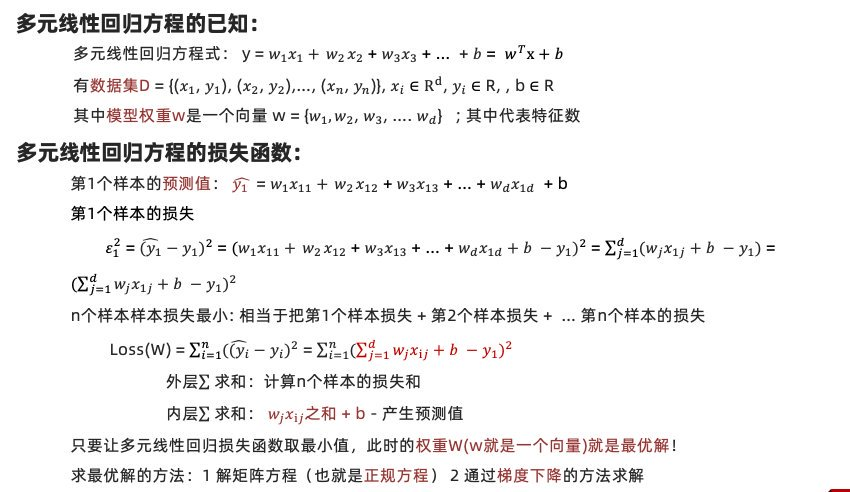

若特征重复、存在完全线性关系，矩阵可能不可逆，参数解不唯一。实践中推荐最小二乘求解或伪逆，避免直接显式求逆：

```python
import numpy as np

X = np.array([[160.], [166.], [172.], [174.], [180.]])
y = np.array([56.3, 60.6, 65.1, 68.5, 75.0])
X_aug = np.column_stack([np.ones(len(X)), X])
theta, residuals, rank, singular_values = np.linalg.lstsq(
    X_aug, y, rcond=None
)
print("b, k:", theta)
print("预测:", np.array([1., 176.]) @ theta)
```

这里已经显式加入常数列；若再使用模型内置的截距，应避免不必要的重复。`LinearRegression` 使用数值求解器，不能简单理解为它总是执行一行显式矩阵求逆。

### 4.3 正规求解与梯度下降怎样选择

| 比较项 | 最小二乘的数值求解 | 梯度下降 |
|---|---|---|
| 思路 | 通过线性代数求解目标 | 反复沿负梯度更新参数 |
| 学习率 | 无需指定 | 需要设置学习率或调度方式 |
| 特征、样本很多时 | 计算和内存开销可能增大 | 可逐样本或小批量更新 |
| 适用范围 | 线性最小二乘等有特定结构的问题 | 可推广到很多可微目标 |
| 数值注意点 | 共线性、秩、条件数 | 特征尺度、步长、收敛情况 |

在**相同模型、相同平方损失、相同正则设置**下，两种方法优化的是同一个目标。梯度下降充分收敛后可以接近最小二乘解；更换求解方法不会自动让平方损失更抗异常点。异常值敏感性还与损失函数、数据和模型假设有关。

## 5. 梯度下降：不断更新参数，降低损失

梯度下降从一组初始参数开始，每一轮计算当前位置的梯度，再沿相反方向更新：

$$
\boldsymbol\theta^{(t+1)}
=\boldsymbol\theta^{(t)}-\eta\nabla J(\boldsymbol\theta^{(t)})
$$

其中 $\eta$ 是学习率，决定更新的步长。下山类比里，参数是当前位置，损失是海拔，负梯度是当前位置的下降方向。

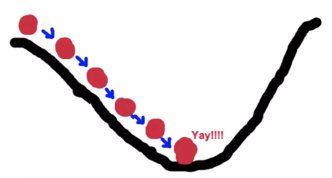

每轮通常执行：计算预测 → 计算残差 → 计算梯度 → 更新参数。停止条件可以是达到最大迭代次数，或者损失改善/参数变化足够小。

学习率过大可能来回震荡甚至发散，过小则收敛慢。课程出现的 `0.001～0.01` 是教学示例范围，并非所有任务都适用；特征尺度、损失的归一化方式也会影响合适的步长。

### 5.1 两个简单的手算迭代

**单变量：** $J(\theta)=\theta^2$，梯度为 $2\theta$。从 $\theta_0=1$ 出发，取 $\eta=0.4$：

$$
\theta_{t+1}=\theta_t-0.4(2\theta_t)=0.2\theta_t
$$

| 轮次 | 参数 | 损失 |
|---|---:|---:|
| 0 | 1 | 1 |
| 1 | 0.2 | 0.04 |
| 2 | 0.04 | 0.0016 |
| 3 | 0.008 | 0.000064 |
| 4 | 0.0016 | 0.00000256 |

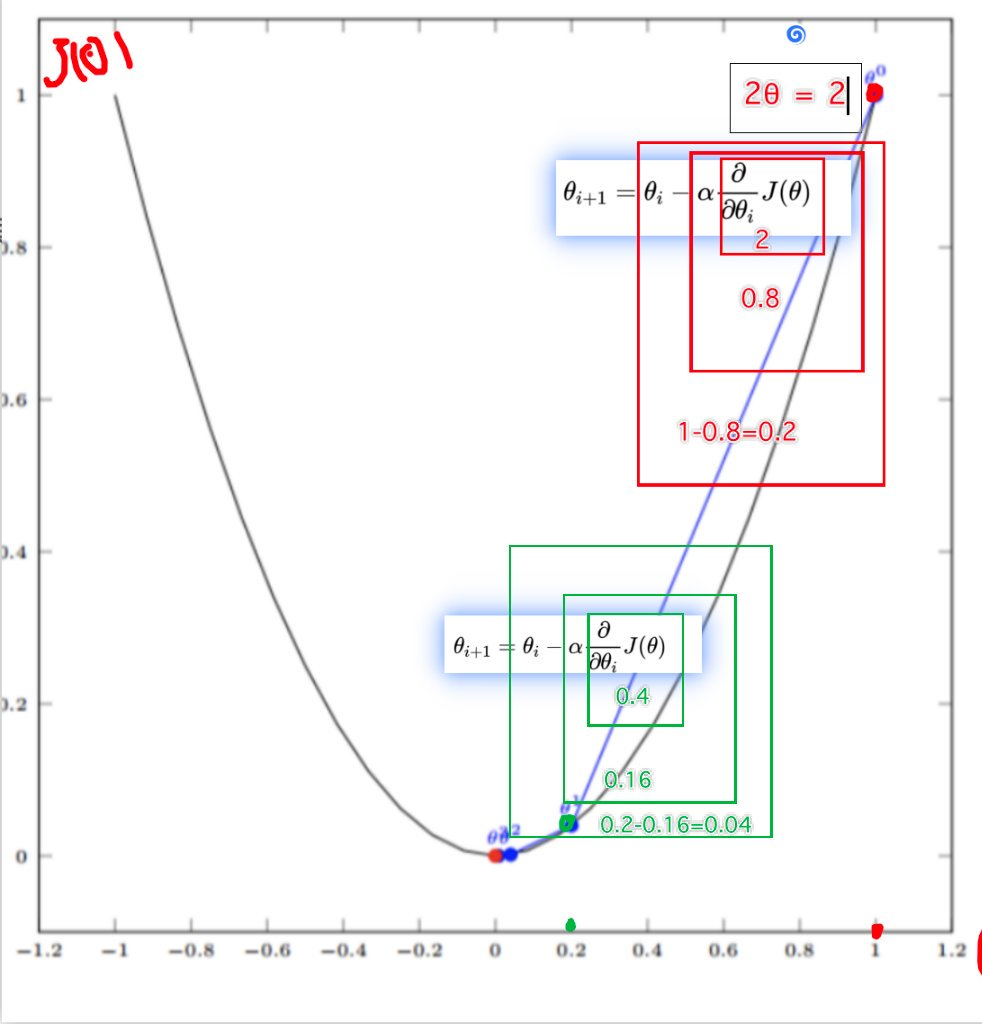

**多变量：** $J(\theta_1,\theta_2)=\theta_1^2+\theta_2^2$，梯度为 $(2\theta_1,2\theta_2)$。从 $(1,3)$ 出发，取 $\eta=0.1$，依次更新为 $(0.8,2.4)$、$(0.64,1.92)$。

所有参数的梯度应基于**同一轮的旧参数**计算，然后统一更新；不要刚修改第一个参数，就拿新参数计算其他分量。

### 5.2 银行信贷案例：推导第一轮梯度

本例沿用课件的模拟数据，用来练习多元回归计算。输入为月工资、存款余额、房产面积，目标为额度：

| 编号 | 月工资 | 存款余额 | 房产面积 | 额度 |
|---|---:|---:|---:|---:|
| 1 | 6000 | 12000 | 55 | 30000 |
| 2 | 8000 | 10000 | 65 | 45300 |
| 3 | 7500 | 16000 | 60 | 46000 |
| 4 | 10000 | 15000 | 75 | 55500 |
| 5 | 9000 | 21000 | 70 | 58000 |
| 6 | 12000 | 19000 | 85 | 75400 |
| 7 | 11000 | 26000 | 90 | 81000 |
| 8 | 13000 | 32000 | 80 | 76800 |

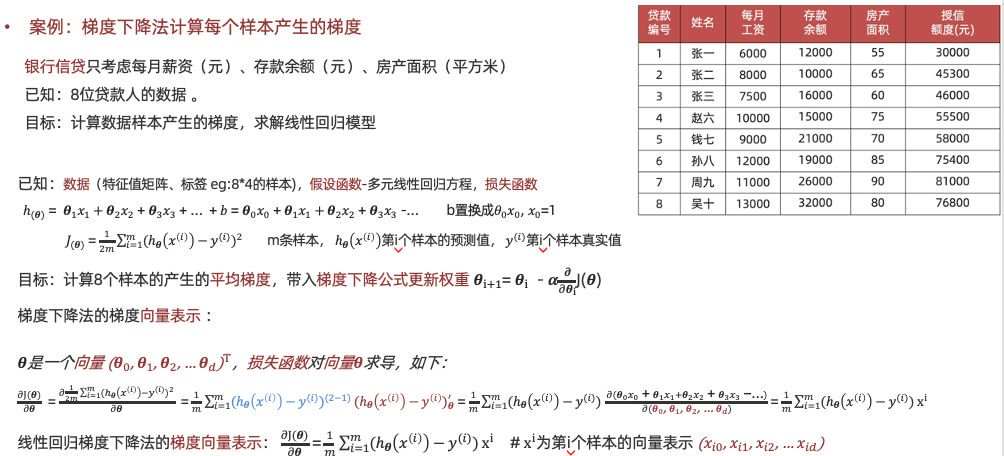

令 $x_{i0}=1$，初始参数 $\boldsymbol\theta=(1,1,1,1)$，使用：

$$
h_\theta(x_i)=\theta_0+\theta_1x_{i1}+\theta_2x_{i2}+\theta_3x_{i3},
\qquad J=\frac1{2m}\sum_i(h_\theta(x_i)-y_i)^2
$$

第一个样本的预测为 $1+6000+12000+55=18056$，残差 $e_1=18056-30000=-11944$。全部残差为：

$$
(-11944,-27234,-22439,-30424,-27929,-44314,-43909,-31719)
$$

梯度分量为 $\frac{\partial J}{\partial\theta_j}=\frac1m\sum_i e_ix_{ij}$。取 $\eta=0.001$，核算结果：

| 参数 | 平均梯度 | 第一轮更新后的参数 |
|---|---:|---:|
| 偏置 $\theta_0$ | -29989 | 30.989 |
| 工资权重 $\theta_1$ | -305067937.5 | 305068.9375 |
| 存款权重 $\theta_2$ | -602021125 | 602022.125 |
| 面积权重 $\theta_3$ | -2283290 | 2284.29 |

原课工资权重更新处存在数字排版/计算问题，上表以同一公式统一重算。输入未经缩放，导致部分梯度特别大；这个学习率适合说明“一步怎样算”，**不适合直接持续训练这些原始数据**。

### 5.3 用 NumPy 核对梯度，再用标准化改善尺度

```python
import numpy as np

X = np.array([
    [6000, 12000, 55], [8000, 10000, 65],
    [7500, 16000, 60], [10000, 15000, 75],
    [9000, 21000, 70], [12000, 19000, 85],
    [11000, 26000, 90], [13000, 32000, 80]
], dtype=float)
y = np.array([30000, 45300, 46000, 55500,
              58000, 75400, 81000, 76800], dtype=float)

A = np.column_stack([np.ones(len(X)), X])
theta = np.ones(A.shape[1])
errors = A @ theta - y
gradient = A.T @ errors / len(X)
theta_next = theta - 0.001 * gradient
print("残差:", errors)
print("梯度:", gradient)
print("下一轮参数:", theta_next)

# 下面重新开始，用标准化后的 X 演示稳定一些的批量迭代。
# 全部 8 个样本只用于优化教学，这里没有做泛化效果评估。
Xs = (X - X.mean(axis=0)) / X.std(axis=0)
As = np.column_stack([np.ones(len(Xs)), Xs])
theta_s = np.zeros(As.shape[1])
for _ in range(20000):
    gradient_s = As.T @ (As @ theta_s - y) / len(Xs)
    theta_s = theta_s - 0.1 * gradient_s
print("标准化空间中的参数:", theta_s)
print("训练 MSE:", np.mean((As @ theta_s - y) ** 2))
```

标准化后的权重对应“特征增加一个标准差”，与原始单位下的权重含义不同。对于正式预测流程，应先划分训练集和测试集，再仅用训练集拟合标准化器；这里的 8 个样本是梯度练习，不是可用于实际授信决策的模型。

### 5.4 梯度下降的常见类型

| 方法 | 一次更新用多少数据 | 特点 |
|---|---|---|
| 批量/全梯度下降 BGD、FGD | 全部训练样本 | 梯度较稳定，一次更新的计算量较大 |
| 随机梯度下降 SGD | 一个样本 | 更新频繁，梯度有噪声，可适合在线学习 |
| 小批量梯度下降 Mini-batch GD | 一小批样本 | 在计算效率与梯度噪声之间折中 |
| 随机平均梯度 SAG | 更新一个样本梯度并利用历史梯度 | 保存历史信息以减小波动；是课件补充介绍的方法 |

一轮 `epoch` 通常表示遍历一次训练数据；一次 `iteration` 表示一次参数更新，两者不能直接等同。

普通线性回归的平方损失是凸函数，讨论 SGD 时应关注噪声、步长与收敛；不能机械套用“容易困在局部最小值”的说法。`SGDRegressor` 没有通用的 `batch_size` 构造参数，小批量算法是概念层面的补充。

### 5.5 LinearRegression 与 SGDRegressor 的 API

```python
from sklearn.linear_model import LinearRegression, SGDRegressor

ols = LinearRegression(fit_intercept=True)
sgd = SGDRegressor(
    loss="squared_error",
    penalty=None,
    fit_intercept=True,
    learning_rate="constant",
    eta0=0.01,
    max_iter=10000,
    tol=1e-5,
    random_state=22
)
```

| 参数/属性 | 作用 |
|---|---|
| `fit_intercept` | 是否学习截距；设为 False 要有适当理由 |
| `loss` | 优化的损失类型，平方误差用 `"squared_error"` |
| `penalty` | 正则化设置；`None` 表示不加惩罚 |
| `learning_rate` | 学习率策略，例如 constant、invscaling |
| `eta0` | 初始学习率，具体使用方式取决于策略 |
| `max_iter`、`tol` | 最大遍历轮数与停止条件 |
| `random_state` | 控制随机过程，便于复现 |
| `coef_`、`intercept_` | 训练后的权重与截距 |

原课的 `loss="squared_loss"` 是旧名称，新版改为 `"squared_error"`。`SGDRegressor` 默认带 L2 正则化；若想与无正则最小二乘公平比较，需显式使用 `penalty=None`，并检查是否充分收敛。仅设置相同学习率不能保证不同数据集或目标尺度的训练效果相同。

## 6. 回归评估：MAE、MSE 与 RMSE

模型训练好后，用**未参与训练的样本**比较预测值与真实值。令 $e_i=\hat y_i-y_i$，常见指标为：

$$
\mathrm{MAE}=\frac1m\sum_i|e_i|,
\qquad
\mathrm{MSE}=\frac1m\sum_i e_i^2,
\qquad
\mathrm{RMSE}=\sqrt{\frac1m\sum_i e_i^2}
$$

| 指标 | 直观含义 | 单位 | 对大误差的反应 |
|---|---|---|---|
| MAE，平均绝对误差 | 平均偏差多少 | 与目标一致 | 线性增长 |
| MSE，均方误差 | 平均平方偏差 | 目标单位的平方 | 平方放大 |
| RMSE，均方根误差 | 将均方误差恢复到目标单位 | 与目标一致 | 比 MAE 更强调较大的误差 |

例如体重用 kg 表示，MAE、RMSE 的单位是 kg，MSE 的单位是 kg²。在相同评估条件下，这三个误差通常越小越好，但衡量侧重点不同。

对同一批误差，总有：

$$
\mathrm{RMSE}\ge\mathrm{MAE}
$$

所有样本的绝对误差相同时取等号；原课“RMSE 总大于 MAE”的表述应改为大于或等于。误差为 1 和 3 时，MAE 为 2，RMSE 为 $\sqrt5\approx2.236$。

### 6.1 为什么没有一个指标适合所有情况

原课先用直线 $y=2x+5$ 拟合带少量噪声的数据：

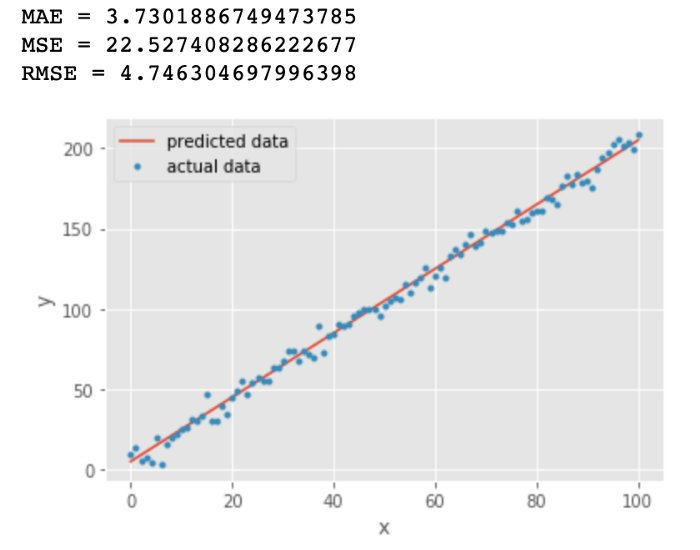

加入随 $x$ 增大的偏差后，部分误差明显变大，RMSE 增幅更明显：

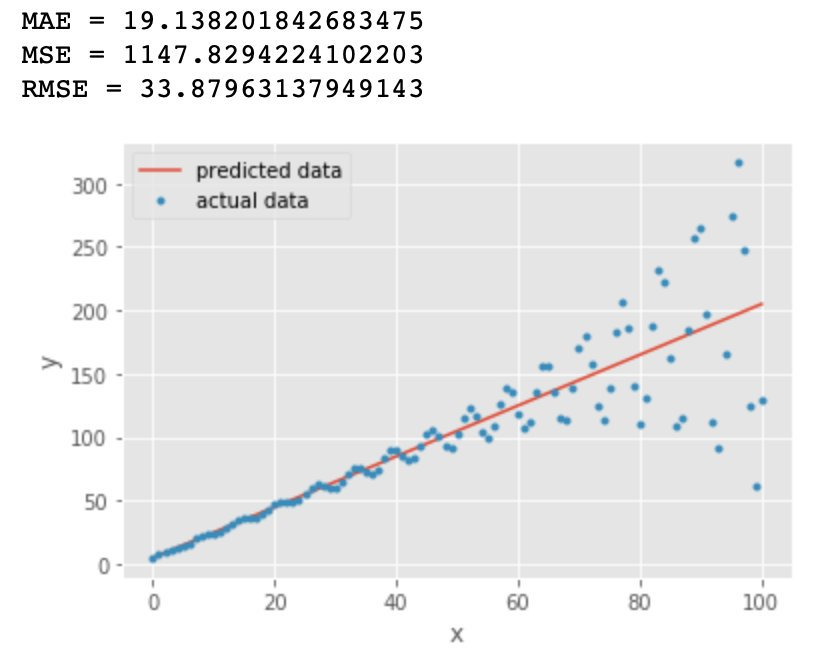

两图上的数值是**原课图示记录**。它们用来观察指标的反应，不能当作本笔记房价案例的输出。

如果较大的预测失误需要付出更高代价，MSE/RMSE 的平方惩罚有帮助；如果希望更直接地描述平均绝对偏差，MAE 更容易解释。MAE 仍受异常误差影响，只是增长速度不像平方误差那么快。

比较模型时，应使用相同目标尺度、可比的数据分布，最好在同一测试集上比较。样本数不同不意味着数学上绝对不能比较，但会影响估计的不确定性；不能把不同任务、不同单位的误差数字直接排大小。

### 6.2 评估指标的代码

```python
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = np.array([10., 20.])
y_pred = np.array([11., 23.])
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
print("MAE:", mae)    # 2.0
print("MSE:", mse)    # 5.0
print("RMSE:", rmse)  # 约 2.23606798
```

新版也可使用 `root_mean_squared_error`。这里用 `np.sqrt(mean_squared_error(...))`，避免依赖部分旧代码中的 `squared=False` 参数。

`model.score(X, y)` 对这些回归模型返回的是 $R^2$，不是分类准确率，也不是 MSE。$R^2$ 可以为负；如果目标是比较 MSE，应显式调用 `mean_squared_error`。

## 7. 原课案例：波士顿房价预测

### 7.1 数据与版本变化

原课使用 Boston Housing 数据：**506 个样本、13 个输入特征**，目标 `MEDV` 为相应地区自住房价格中位数，单位为千美元。样本代表地区统计信息，不能理解为 506 套房屋的逐套交易记录。

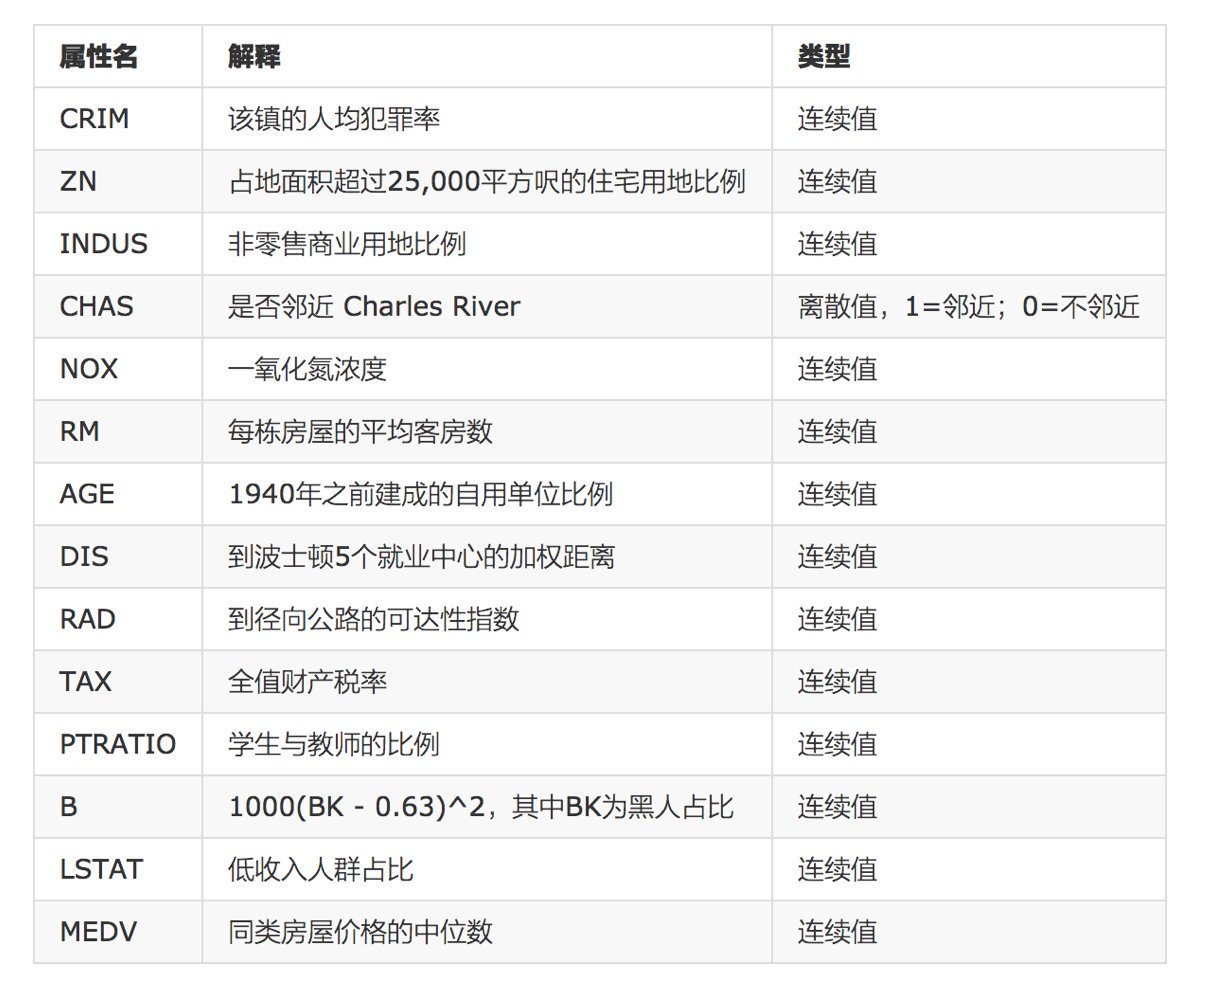

部分字段例子：`RM` 表示平均房间数，`NOX` 表示氮氧化物浓度，`PTRATIO` 表示师生比例；`MEDV` 是预测目标，不能混入输入特征。

原课使用：

```python
# 历史写法，只用于识别原课代码；新版不执行这两行。
# from sklearn.datasets import load_boston
# boston = load_boston()
```

**`load_boston` 自 scikit-learn 1.2 起已移除**。该历史数据包含有争议的种族相关变量及建模背景；本篇保留它是为了对照课程理解流程。新练习可采用下文无需联网的 `load_diabetes`，或住房主题的 California Housing 数据。

教师笔记使用 `test_size=0.2, random_state=22`；课件部分代码未显式指定 `test_size`，默认会是 0.25。本笔记的 Boston 流程统一按教师笔记的 0.2 划分。

### 7.2 保留原课的外部数据兼容读取方式

教师笔记提供了从原始文本重建数据的方式。每个样本跨两行：第一行有 11 个特征，第二行前两个数是剩余特征，第三个数是目标值。

```python
import numpy as np
import pandas as pd

data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)

X_boston = np.hstack([
    raw_df.values[::2, :],      # 每个样本的前 11 个特征
    raw_df.values[1::2, :2]     # 后 2 个特征
])
y_boston = raw_df.values[1::2, 2]
print(X_boston.shape, y_boston.shape)  # 格式正确时为 (506, 13)、(506,)
```

这是原课外部地址，需要联网，受源站可用性与文件格式影响；本篇未将该网络读取结果记为已运行输出。若读取失败，可以从课程资料中找到对应数据文件后修改为本地路径，或直接使用后面的离线替代案例，不要把 HTML 错误页面当成数据继续训练。

### 7.3 正确的数据处理顺序

1. 划分训练集和测试集。
2. 在训练集上学习预处理参数。
3. 用相同预处理规则变换训练集和测试集。
4. 仅使用训练集训练模型。
5. 在测试集计算预测误差。

标准化公式：

$$
x'_{ij}=\frac{x_{ij}-\mu_j}{s_j}
$$

$\mu_j,s_j$ 来自训练集。测试集只执行 `transform`；如果用全量数据先拟合标准化器，会提前利用测试集信息。

`Pipeline` 将标准化与模型串成一个流程。在交叉验证时，每一折都只在该折训练数据上学习标准化参数，更容易避免数据泄漏。

标准化对 SGD 的优化速度和对正则项的公平性尤其有帮助。对带截距、无正则且充分求解的普通最小二乘，非退化的特征缩放理论上不改变能拟合出的预测集合，主要改变参数表示与数值条件；不能笼统说所有线性回归都必须缩放才能预测。

### 7.4 比较最小二乘与 SGD 的 Boston 流程

下面代码接在 7.2 的数据读取之后执行。显式设置 `penalty=None`，使 SGD 与无正则最小二乘尽量优化相同的目标。

```python
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X_boston, y_boston, test_size=0.2, random_state=22
)
models = {
    "最小二乘": make_pipeline(StandardScaler(), LinearRegression()),
    "SGD": make_pipeline(
        StandardScaler(),
        SGDRegressor(
            loss="squared_error", penalty=None,
            learning_rate="invscaling", eta0=0.01,
            max_iter=20000, tol=1e-5, random_state=22
        )
    )
}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    print(name,
          "MAE:", mean_absolute_error(y_test, pred),
          "MSE:", mean_squared_error(y_test, pred),
          "RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
```

课程主要使用 constant 学习率；这里用 invscaling 演示逐渐减小步长的写法。若比较两种求解方法的差异，应同时检查迭代是否收敛、训练目标是否一致，而不是仅比较类名。

出现 `ConvergenceWarning` 时，先检查特征尺度、学习率、迭代次数和容差；不要直接忽略警告并把结果认定为最优解。

### 7.5 无需联网的完整替代练习

`load_diabetes` 是 scikit-learn 自带的回归教学数据，目标是某种疾病进展的数值指标。它用于练习同样的数据处理流程；目标与房价不同，因此误差数字也不能与房价结果直接比较。

```python
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=22
)
models = {
    "OLS": make_pipeline(StandardScaler(), LinearRegression()),
    "SGD": make_pipeline(
        StandardScaler(),
        SGDRegressor(
            loss="squared_error", penalty=None,
            learning_rate="invscaling", eta0=0.01,
            max_iter=20000, tol=1e-5, random_state=22
        )
    )
}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name,
          "MAE =", round(mean_absolute_error(y_test, pred), 3),
          "MSE =", round(mean_squared_error(y_test, pred), 3),
          "RMSE =", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
```

这段代码包含完整导入与数据获取，可以独立复制运行。每次运行固定随机种子有助于复现，但软件版本、数值库和停止条件仍可能造成细微差别。

本次在 scikit-learn 1.9.1 下执行上述代码，得到以下参考结果：

| 模型 | MAE | MSE | RMSE |
|---|---:|---:|---:|
| OLS | 43.677 | 3187.806 | 56.461 |
| SGD | 43.838 | 3192.509 | 56.502 |

两种求解方式在这次设置下结果接近。这里所有指标都对应 diabetes 的同一测试集，不能解读为房价误差或疾病诊断准确率。

### 7.6 怎样解释回归系数

在模型中，如果其他输入保持不变，$x_j$ 增加 1 单位，预测值变化 $w_j$。若使用标准化特征，增加 1 代表增加训练集中的一个标准差。

因此比较权重大小之前，必须考虑特征尺度：工资以“元”为单位还是“万元”为单位，得到的权重数值会不同，预测可以完全相同。特征相关性也可能让系数不稳定。

标准化模型为：

$$
\hat y=\sum_jw'_j\frac{x_j-\mu_j}{s_j}+b'
$$

恢复原始单位：

$$
w_j=\frac{w'_j}{s_j},\qquad
b=b'-\sum_j\frac{w'_j\mu_j}{s_j}
$$

系数反映模型中的条件关系，不能仅凭“权重大”推断因果影响更大。房价、信贷等教学案例中的相关性也不等于真实业务里的因果规律。

## 8. 欠拟合与过拟合

**欠拟合**：模型过于简单，训练集误差就较大，未能抓住数据中的有效规律。

**过拟合**：模型过于复杂，训练集误差很小，但测试集或未来数据误差变大，模型把噪声也当成了规律。

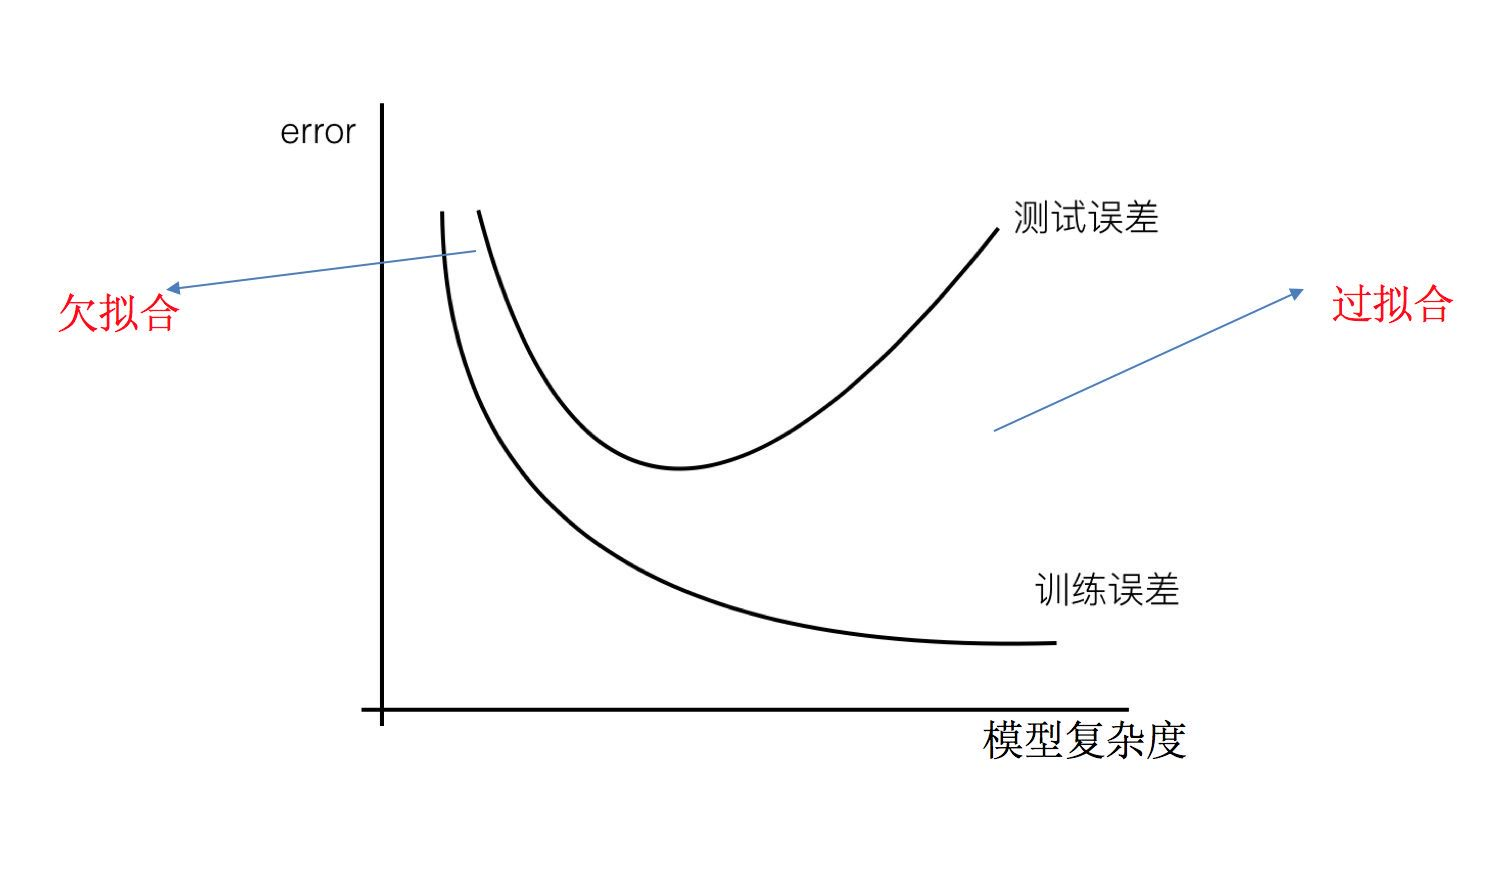

常见诊断：

| 现象 | 训练误差 | 验证/测试误差 | 可能原因 |
|---|---:|---:|---|
| 欠拟合 | 大 | 大 | 特征不足、模型太简单、优化未收敛 |
| 拟合合适 | 较小 | 较小且接近 | 复杂度与数据规模匹配 |
| 过拟合 | 很小 | 明显变大 | 特征噪声、模型太复杂、训练样本不足 |

训练集误差越来越小并不能证明泛化越来越好。应在训练集上学习，在验证集上选择特征、次数和超参数，最后只用测试集做一次最终报告。若数据量允许，还可以使用交叉验证。

### 8.1 用多项式特征观察三种状态

数据由二次函数加噪声生成：

$$
y=0.5x^2+x+2+\varepsilon,\qquad \varepsilon\sim\mathcal N(0,1)
$$

`PolynomialFeatures` 把一个输入 $x$ 扩展为 $x,x^2,\ldots,x^d$。虽然输出曲线可以弯曲，模型对扩展后的参数仍然是线性的。

```python
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

rng = np.random.RandomState(666)
x = rng.uniform(-3, 3, size=100)
y = 0.5 * x**2 + x + 2 + rng.normal(0, 1, size=100)
X = x.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=5
)

for degree in [1, 2, 5, 10]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X_train, y_train)
    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse = mean_squared_error(y_test, model.predict(X_test))
    print(degree, "train MSE =", train_mse, "test MSE =", test_mse)
```

用同一随机数据、`random_state=5` 划分时，本次核算的测试集 MSE 约为：

| 次数 | 训练 MSE | 测试 MSE | 解释 |
|---:|---:|---:|---|
| 1 | 3.0496 | 3.1531 | 欠拟合，直线无法表达明显弯曲 |
| 2 | 1.0951 | 1.1119 | 与真实规律匹配较好 |
| 5 | 1.0559 | 1.2079 | 测试误差开始上升，出现过拟合倾向 |
| 10 | 0.9992 | 1.4146 | 训练误差继续下降，泛化变差 |

> 教师笔记中“X5 测试误差为 1.414558…”的片段未定义 X5。按同一随机数据与划分重算，五次项约为 1.207891，十次项约为 1.414558；该记录实际对应十次特征的结果。

不同版本或划分参数可能产生不同的小数；重点是观察“训练误差下降而验证/测试误差先降后升”的趋势。绘制曲线时应先按 $x$ 排序，或在连续的 `x_grid` 上预测，否则折线会来回连接而产生误导。

### 8.2 看曲线，也看评估数据的来源

原课先在全部 100 个样本上训练并计算同一批数据的误差，用于观察拟合程度：

| 特征次数 | 全量拟合后的训练 MSE |
|---:|---:|
| 1 | 3.07500258 |
| 2 | 1.09873921 |
| 10 | 1.05084668 |

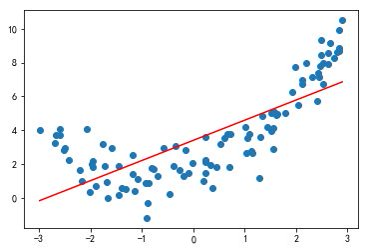

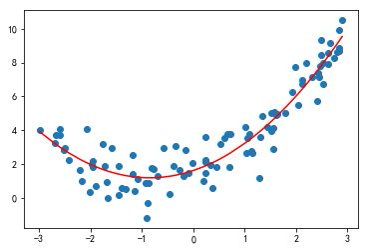

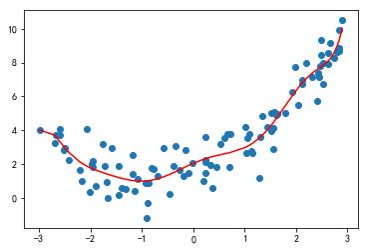

这些全量训练误差与上一节“划分后只在 75 个训练样本上拟合”的训练误差不同；不能把它们放在同一列冒充同一次实验。曲线外观只是提示，判断过拟合仍要用独立验证数据。

下面代码独立生成同一批数据，用均匀网格画曲线，避免未排序的横坐标把线来回连接：

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

rng = np.random.RandomState(666)
x = rng.uniform(-3, 3, 100)
y = 0.5 * x**2 + x + 2 + rng.normal(0, 1, 100)
X = x[:, None]
grid = np.linspace(-3, 3, 300).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, degree in zip(axes, [1, 2, 10]):
    model = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X, y)
    ax.scatter(x, y, s=12)
    ax.plot(grid[:, 0], model.predict(grid), color="red")
    ax.set_title(f"degree = {degree}")
plt.tight_layout()
plt.show()
```

### 8.3 欠拟合、过拟合的处理思路

欠拟合可以尝试：

- 补充有业务依据的有效特征；
- 增加合适的多项式项或换更有表达力的模型；
- 检查学习率、迭代次数和停止条件，确认模型确实收敛；
- 检查特征与目标是否存在非线性或数据质量问题。

过拟合可以尝试：

- 清理错误标签、重复记录和明显的数据问题；
- 增加覆盖真实分布的训练样本；
- 减少无效特征或降低多项式次数；
- 引入 L1/L2 正则化；
- 用验证集或交叉验证选择复杂度。

“删掉所有异常点”不是通用方案：异常点可能是真实而重要的样本，应先确认它是录入错误、分布变化还是业务中确实需要覆盖的情况。

## 9. 正则化：给过于复杂的模型增加代价

在数据损失之外加入参数惩罚：

$$
J_{\mathrm{reg}}(\boldsymbol w)
=J_{\mathrm{data}}(\boldsymbol w)+\lambda\Omega(\boldsymbol w)
$$

$\lambda\ge0$ 是超参数。惩罚通常作用于特征权重，不惩罚截距；具体实现以模型定义为准。$\lambda$ 越大，参数越受限制，太大可能导致欠拟合。

### 9.1 L1 正则化与 Lasso

$$
J_{\mathrm{L1}}
=J_{\mathrm{data}}+\lambda\sum_j|w_j|
$$

L1 在 0 处不可导，严格推导使用次梯度：

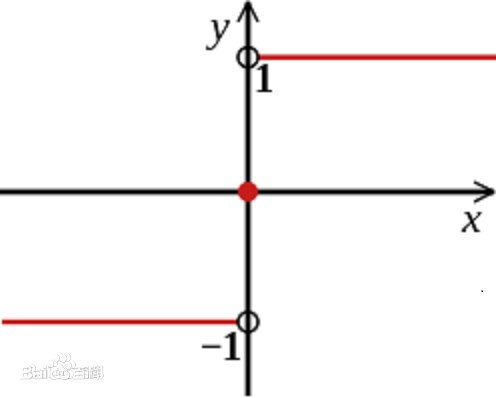

$$
\partial|w|=
\begin{cases}
\{1\},&w>0\\
[-1,1],&w=0\\
\{-1\},&w<0
\end{cases}
$$

L1 的几何约束容易让部分权重精确变为 0，得到稀疏解，可用于特征选择；但“权重为 0”也可能是共线特征之间的选择，不应未经验证就解释为该特征毫无现实作用。

```python
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.005, max_iter=10000)
```

### 9.2 L2 正则化与 Ridge

$$
J_{\mathrm{L2}}
=J_{\mathrm{data}}+\lambda\sum_jw_j^2
$$

L2 的梯度在 0 处连续，会把权重整体压小，通常保留非零系数，对共线特征更稳定：

$$
\frac{\partial}{\partial w_j}\lambda w_j^2=2\lambda w_j
$$

```python
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=0.005)
```

原课的 `alpha=0.005` 只是教学示例，不代表最优超参数。应使用训练集内部的交叉验证选择 alpha，并对输入做合适缩放。Lasso 与 Ridge 的 alpha 定义、损失归一化和实现细节不同，不能只凭同一个数字比较惩罚强度。

### 9.3 在高次多项式上比较无正则、L1、L2

```python
import numpy as np
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

rng = np.random.RandomState(666)
x = rng.uniform(-3, 3, size=100)
y = 0.5 * x**2 + x + 2 + rng.normal(0, 1, size=100)
X = x.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=5
)

def pipeline(estimator):
    return make_pipeline(
        PolynomialFeatures(degree=10, include_bias=False),
        StandardScaler(),
        estimator
    )

models = {
    "OLS": pipeline(LinearRegression()),
    "Lasso": pipeline(Lasso(alpha=0.01, max_iter=10000)),
    "Ridge": pipeline(Ridge(alpha=1.0))
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name,
          "train MSE =", mean_squared_error(y_train, model.predict(X_train)),
          "test MSE =", mean_squared_error(y_test, model.predict(X_test)))
```

`StandardScaler` 放在多项式特征之后，可以让不同次幂处在更可比的尺度；`Pipeline` 保证每次划分只用训练部分拟合缩放器。缩放会改变惩罚的数值尺度，因此不能假称它与旧版 `normalize=True` 完全等价，而应重新选择 alpha。

原课的 `Lasso(alpha=0.005)`、`Ridge(alpha=0.005)` 保留作为接口示例；新版不再支持回归器中的 `normalize=True`，推荐显式使用 Pipeline。

本次执行上面的十次特征示例得到：

| 模型 | 训练 MSE | 测试 MSE |
|---|---:|---:|
| OLS | 0.9992 | 1.4146 |
| Lasso | 1.0517 | 1.2136 |
| Ridge | 1.0554 | 1.2273 |

两个正则模型牺牲了一些训练集拟合程度，换来这次测试集上较小的误差。这只能说明这组数据与参数下的效果；不能保证正则化在任意数据上都改善测试误差。

### 9.4 读懂课程的正则化效果图

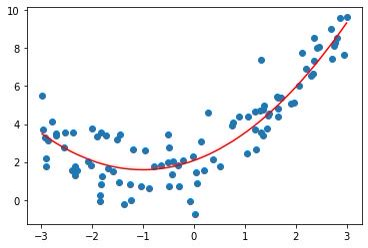

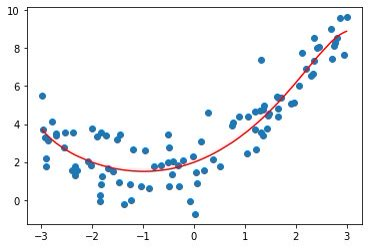

这两图来自课程原始参数设置，只展示曲线在这组样本上的形状。第 9.3 节代码增加了特征缩放、训练测试划分并调整了示例 alpha，因此运行出的系数和曲线不必与原图完全一致。

两个实现的目标定义也有区别：

$$
J_{\mathrm{Lasso}}=\frac1{2m}\|y-Xw-b\|_2^2
+\alpha\|w\|_1
$$

$$
J_{\mathrm{Ridge}}=\|y-Xw-b\|_2^2+\alpha\|w\|_2^2
$$

同样带 L2 惩罚的 SGDRegressor 使用另一种目标归一化；相同 alpha 不保证与 Ridge 得到相同参数。

Lasso 的精确零系数由优化过程产生；不能把“符号函数在 0 处定义为 0”误当成“绝对值在 0 处可导”，也不能把普通减梯度一步必然跨过 0 当作稀疏性的完整证明。

### 9.5 用交叉验证选择正则化强度

下面给出课后 L1/L2 练习的完整模板。所有标准化都在交叉验证各折内部拟合；最终测试集只用于评估选好的两个模型。

```python
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=22
)
cv = KFold(n_splits=5, shuffle=True, random_state=22)
for estimator in [Ridge(), Lasso(max_iter=20000)]:
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("reg", estimator)
    ])
    search = GridSearchCV(
        pipeline,
        {"reg__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]},
        scoring="neg_mean_squared_error",
        cv=cv
    )
    search.fit(X_train, y_train)
    pred = search.predict(X_test)
    print(type(estimator).__name__,
          "alpha =", search.best_params_["reg__alpha"],
          "CV MSE =", -search.best_score_,
          "test MAE =", mean_absolute_error(y_test, pred),
          "test RMSE =", np.sqrt(mean_squared_error(y_test, pred)))
```

scikit-learn 的搜索接口按“得分越大越好”选模型，因此 MSE 用负值形式。`-search.best_score_` 才是验证折上的平均 MSE。测试误差与交叉验证误差不必完全一致；不要再根据测试集反复扩展参数网格。

### 9.6 L1 与 L2 的选型提醒

| 需求 | 优先考虑 | 说明 |
|---|---|---|
| 希望得到少量非零特征 | L1/Lasso | 需要检查特征缩放和共线性 |
| 特征很多且相关，想稳定收缩 | L2/Ridge | 通常不产生精确 0 |
| 不确定哪种更合适 | ElasticNet 或交叉验证比较 | 同时包含 L1 与 L2 |

正则化是对参数复杂度施加偏好，不是自动清理异常样本，也不能保证“只清除高次项”。真实项目还要检查数据泄漏、标签质量、时间切分和业务约束。

## 10. 从数据到回归模型的检查清单

1. 明确目标是连续数值，区分回归与分类。
2. 检查每列特征的含义、单位、缺失值、异常值和重复记录。
3. 划分训练、验证、测试数据；时间数据按时间切分。
4. 只用训练数据拟合缺失值填补器、标准化器、特征选择器。
5. 先用简单的线性模型建立基线，再增加多项式项或正则化。
6. 同时查看训练误差、验证误差和测试误差；不能只看训练 MSE。
7. 用与任务代价相符的 MAE、MSE、RMSE 等指标，报告目标单位。
8. 用 Pipeline 和交叉验证选择 alpha、次数、学习率等超参数。
9. 检查残差图、预测值范围和数据分布漂移。
10. 记录随机种子、软件版本、数据版本和实验设置。

## 11. 课后练习

### 基础题

1. 用五组身高体重数据手算 $\sum x_i,\sum y_i,\sum x_i^2,\sum x_iy_i$，由两个正规方程求出 $k,b$，再与 `LinearRegression` 比较。
2. 取 $J(\theta)=\theta^2$，分别用 $\eta=0.1,0.6,1.1$ 手算五轮，观察收敛、震荡和发散的差异。
3. 对银行案例写出偏置、工资、存款、面积四个梯度的求和式，再用 NumPy 核对第一轮参数。

### 实践题

4. 在 `load_diabetes` 上比较 LinearRegression、Ridge、Lasso，使用训练集内部的 `GridSearchCV` 选择 alpha，并在最终测试集只评估一次。
5. 生成 1、2、5、10 次多项式特征，绘制训练/验证误差曲线；说明你选择次数的依据。
6. 在同一测试集上分别报告 MAE、MSE、RMSE，构造一个含有少量大误差的预测结果，说明 RMSE 为何上升更快。
7. 对 Boston 兼容数据流程实现 L1/L2 正则化；若外部地址不可用，说明限制并用离线数据替代，不要伪造运行结果。

### 思考题

8. 为什么把工资从“元”改成“万元”会改变回归系数，但可以不改变预测？
9. 为什么在 L1/L2 正则化前通常要缩放特征？
10. 梯度为 0 什么时候能说明是最小值？请给出一个导数为 0 但不是极值的函数。

## 12. 易错点速查

- `X` 必须是二维；单特征数据使用 `X.reshape(-1, 1)`。
- NumPy `*` 是逐元素乘法，`@` 才是矩阵乘法。
- 预测阶段只调用 `transform`，不要对测试集再次 `fit_transform`。
- 训练误差降低不等于泛化变好；过拟合要看验证/测试误差。
- RMSE 与 MAE 同单位，MSE 是平方单位；RMSE $\ge$ MAE。
- `load_boston` 已移除，旧代码不能在新版 sklearn 中直接运行。
- `SGDRegressor(loss="squared_loss")` 是旧写法，新版用 `"squared_error"`。
- `SGDRegressor` 默认有 L2 惩罚，公平比较 OLS 时设置 `penalty=None`。
- `Lasso/Ridge(normalize=True)` 已移除，用 Pipeline + StandardScaler，并重调 alpha。
- 画高次曲线时先按横坐标排序，或用连续网格预测。
- 权重大小受单位、缩放和共线性影响，不能单独解释为因果重要性。
- 银行数据只是梯度下降手算练习，不是实际信贷审批模型。

## 13. 本篇小结

线性回归用参数的线性组合预测连续目标；平方损失把“找一条合适的线”变成了可优化的问题。正规方程从线性代数直接求解，梯度下降通过反复更新参数逼近低损失区域。MAE、MSE、RMSE 从不同角度衡量误差，选择指标要结合异常值影响和业务代价。

多项式特征能提高表达能力，但也会增加过拟合风险。L1 促成稀疏解，L2 收缩权重；二者都需要在正确的数据划分、特征缩放和验证策略下使用。完整流程的核心不是背某一个 API，而是保证数据处理、优化目标和评估方式相互一致。